# Notebook to create Figure 3, Figure 5, and Figure S4

Compares the representation methods at the method level. It needs **both** the
Jaccard pipeline (k=25) and the RDPG pipeline (k=25) to have been run.

- Figure 3: method distance matrix (Jaccard) + its MDS embedding
- Figure 5: matrix of sequences with significantly different representations (RDPG p-values)
- Figure S4: correlation between the Jaccard and RDPG method-level distances

In [1]:
cran_packages <- c(
  "glue", "ggplot2", "reshape2", "ggbreak", "RColorBrewer",
  "stringr", "dendextend", "dplyr", "tidyr", "plotly",
  "ggforce", "purrr", "gplots", "jsonlite"
)

for (pkg in cran_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  } else {
    message(glue::glue("Already installed package: {pkg}"))
  }
  library(pkg, character.only = TRUE)
}

library(stats)

Already installed package: glue

Already installed package: ggplot2

Already installed package: reshape2

Already installed package: ggbreak

ggbreak v0.1.6 Learn more at https://yulab-smu.top/



If you use ggbreak in published research, please cite the following
paper:

S Xu, M Chen, T Feng, L Zhan, L Zhou, G Yu. Use ggbreak to effectively
utilize plotting space to deal with large datasets and outliers.
Frontiers in Genetics. 2021, 12:774846. doi: 10.3389/fgene.2021.774846


Already installed package: RColorBrewer

Already installed package: stringr

Already installed package: dendextend


---------------------
Welcome to dendextend version 1.19.1
Type citation('dendextend') for how to cite the package.

Type browseVignettes(package = 'dendextend') for the package vignette.
The github page is: https://github.com/talgalili/dendextend/

Suggestions and bug-reports can be submitted at: https://github.com/talgalili/dendextend/issues
You may ask questions at stackoverflow, use the r and d

In [3]:
# Working directory is set to the Jaccard results so the relative paths below
# resolve correctly (RDPG files are read back via ../../../RDPG/).
sequences_group <- 'bacteria_1'
k <- 25
hyperparameter <- 'euclidean_KNN_k-25_d-0'
path <- glue("../Results/Jaccard_distance/{sequences_group}/jaccard_results")
setwd(path)

ERROR: Error in setwd(path): cannot change working directory


In [4]:
# Helper to turn a symmetric 5x5 method-distance matrix into a heatmap;
# the lower triangle only is shown.
#   - metric "jaccard": mean Jaccard distance between methods
#   - metric "rdpg": number of sequences with significantly different reps (p < 0.05)
distance_matrix_plot <- function(distance_matrix, metric = "jaccard") {
  legend <- switch(metric,
                   "jaccard" = "Jac. dist.",
                   "rdpg" = "Seqs with sig.\n≠ representations")
  matrix_color <- switch(metric,
                   "rdpg" = colorRampPalette(c("#903087", "#f6dff3"))(10),
                   "jaccard" = colorRampPalette(c("#1b7895", "#e7f9ff"))(10))

  df_long <- melt(distance_matrix)
  colnames(df_long) <- c("row", "col", "distance")
  
  df_long$row <- factor(df_long$row, levels = rownames(distance_matrix))
  df_long$col <- factor(df_long$col, levels = colnames(distance_matrix))

  df_long$label <- ifelse(df_long$row == df_long$col, 
                          NA, 
                          sprintf("%.f", df_long$distance))

  df_long$label <- switch(metric,
                   "jaccard" = ifelse(df_long$row == df_long$col, NA, 
                          sprintf("%.2f", df_long$distance)),
                   "rdpg" = ifelse(df_long$row == df_long$col, NA, 
                          sprintf("%.f", df_long$distance)))
  
  df_long$distance[as.numeric(df_long$row) < as.numeric(df_long$col)] <- NA
  df_long$label[as.numeric(df_long$row) < as.numeric(df_long$col)] <- NA

  ggplot(df_long, aes(x = col, y = row, fill = distance)) +
    geom_tile(color = "white") +
    geom_text(aes(label = label), size = 6) +
    scale_fill_gradientn(
      colours = matrix_color,
      name = legend,
      na.value = "white"
    ) + 
    scale_y_discrete(limits = rev(levels(df_long$row))) +
    coord_fixed() +
    theme_minimal(base_size = 14) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1, size = 17),
      axis.text.y = element_text(size = 17),
      axis.title.x = element_blank(),
      axis.title.y = element_blank(),
      legend.title = element_text(size = 17),
      legend.text = element_text(size = 12)
    )
}

In [5]:
# Display order of the five methods
model_names <- c("TNF", "dna2vec", "HyenaDNA", "DNABERT-2", "DNABERT-S")

# 1. Jaccard distances

In [6]:
# Collect the 10 k=25 pairwise Jaccard similarity files produced by the pipeline
jaccard_similarities_files <- list.files(pattern = glue("*_jaccard_similarity_k-{k}.csv"), ignore.case = TRUE)
jaccard_similarities_files

[1] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-25.csv" 
 [2] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-25.csv" 
 [3] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-25.csv"
 [4] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-25.csv"     
 [5] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-25.csv" 
 [6] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-25.csv"
 [7] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-25.csv"
 [8] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-25.csv"     
 [9] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-25.csv"      
[10] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-25.csv"

In [7]:
# Build the 5x5 Jaccard distance matrix: for each pair, read the file, convert
# similarity to distance (1 - sim), take the mean over the 500 sequences and fill
# both symmetric entries.
jacc_distance_matrix <- matrix(0L, nrow = 5, ncol = 5, dimnames = list(model_names, model_names)) 
name_map <- c(
  "dnaberts"  = "DNABERT-S",
  "dnabert2"  = "DNABERT-2",
  "tnf"  = "TNF",
  "hyenadna"  = "HyenaDNA",
  "dna2vec"   = "dna2vec"
)

for (file in jaccard_similarities_files){
  jaccard_similarities <- read.table(file, header = T, sep = '\t')
  jaccard_distances <- 1 - jaccard_similarities
  mean_jaccard_distance <- mean(t(jaccard_distances)[,1])

  models_compared <- strsplit(
    strsplit(file, paste0(sequences_group, "_"))[[1]][2],
    "_jaccard"
  )[[1]][1]

  models <- strsplit(models_compared, "_")[[1]]
  model1 <- name_map[models[1]]
  model2 <- name_map[models[2]]

  jacc_distance_matrix[model1, model2] <- mean_jaccard_distance
  jacc_distance_matrix[model2, model1] <- mean_jaccard_distance
}
jacc_distance_matrix

,TNF,dna2vec,HyenaDNA,DNABERT-2,DNABERT-S
TNF,0.0000000,0.2941119,0.5234759,0.6186010,0.5844321
dna2vec,0.2941119,0.0000000,0.4562530,0.6428551,0.6200939
HyenaDNA,0.5234759,0.4562530,0.0000000,0.7013275,0.6769012
DNABERT-2,0.6186010,0.6428551,0.7013275,0.0000000,0.6793770
DNABERT-S,0.5844321,0.6200939,0.6769012,0.6793770,0.0000000


Warning message:
“Removed 15 rows containing missing values or values outside the scale range (`geom_text()`).”


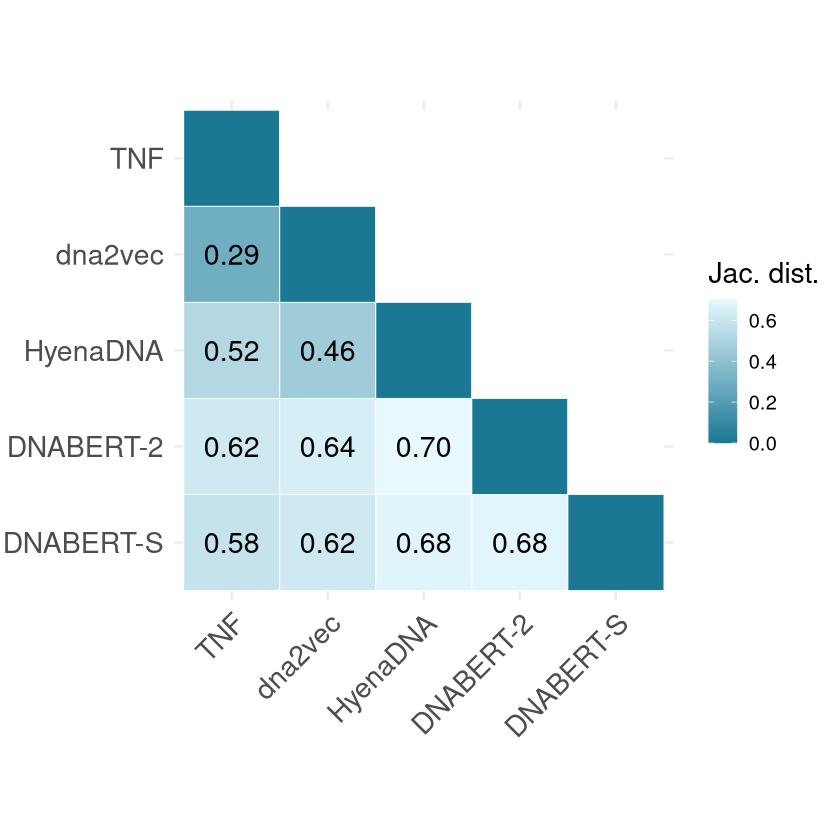

In [8]:
p <- distance_matrix_plot(jacc_distance_matrix)
p

In [9]:
ggsave(
  filename = glue("../../../Plots/{sequences_group}_jaccard_distance_matrix_figure_3a.png"),
  plot = p,
  width = 8,
  height = 6,
  dpi = 500
)

Warning message:
“Removed 15 rows containing missing values or values outside the scale range (`geom_text()`).”


In [10]:
# Classic MDS of the 5x5 Jaccard distance matrix into 2D, to visualise how the
# methods group in a 2D space (Figure 3b).
dist_mat <- as.dist(jacc_distance_matrix)
mds <- cmdscale(dist_mat, k = 2)
mds_df <- as.data.frame(mds)
colnames(mds_df) <- c("Dim1", "Dim2")
mds_df$hjust <- c(1.1, 1.1, 1.05, 1.1, -0.1)
mds_df$vjust <- c(-0.5, -0.5, 1.5, -0.5, 1.2)

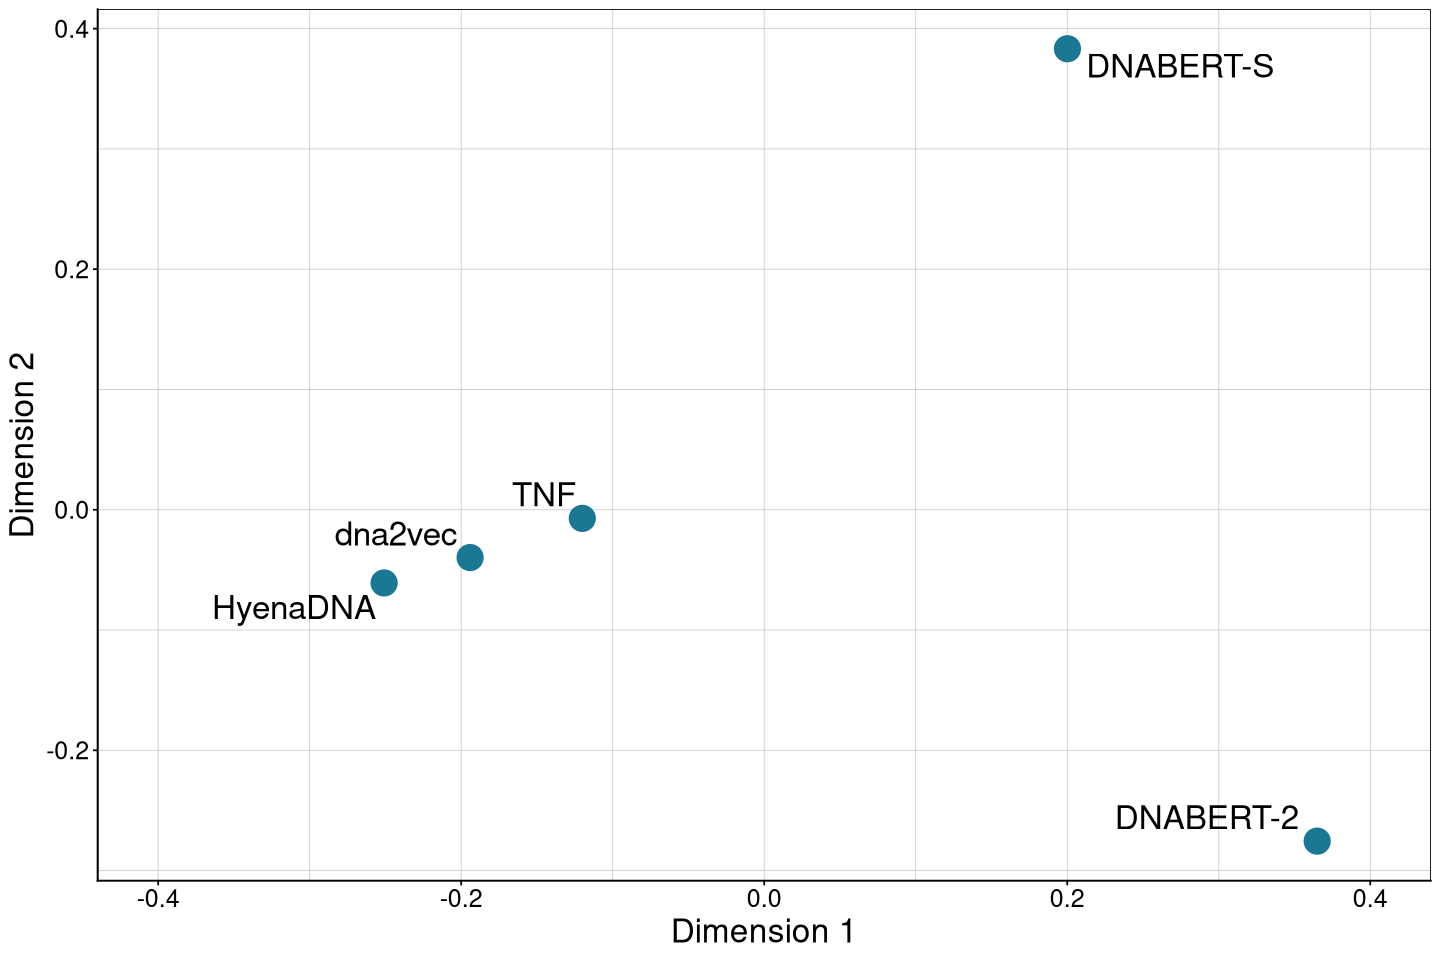

In [12]:
options(repr.plot.width = 12, repr.plot.height = 8)
p <- ggplot(mds_df, aes(x = Dim1, y = Dim2)) +
  geom_point(size = 7, color = "#1b7895") +
  theme_classic() +
  geom_text(aes(label = rownames(mds_df)),
                hjust = mds_df$hjust,
                vjust = mds_df$vjust, 
                size = 7) +
  scale_x_continuous(limits = c(-0.4, 0.4)) +
  labs(
    x = "Dimension 1",
    y = "Dimension 2"
  ) +
  theme(    
    axis.title.x = element_text(size = 20),
    axis.text.x = element_text(size = 15),
    axis.title.y = element_text(size = 20),
    axis.text.y = element_text(size = 15),
    panel.border = element_rect(color = "black", fill = NA, linewidth = 0.5),
    panel.grid.major = element_line(color = "grey80", linewidth = 0.25),
    panel.grid.minor = element_line(color = "grey80", linewidth = 0.25))
p

In [13]:
ggsave(
  filename = glue("../../../Plots/{sequences_group}_jaccard_mds_figure_3b.png"),
  plot = p,
  width = 8,
  height = 6,
  dpi = 500
)

# 2. RDPG statistical test

In [14]:
# Load the RDPG pairwise p-values table (one row per sequence, one column per pair).
p_values = read.table(glue("../../../RDPG/{sequences_group}_p_values_{hyperparameter}.csv"), header = T, sep=',')

In [15]:
# Count, for each method pair, the number of sequences whose representations are
# significantly different (RDPG pairwise test, p < 0.05). These counts fill the
# symmetric 5x5 matrix shown in Figure 5.
stat_matrix <- matrix(0L, nrow = 5, ncol = 5, dimnames = list(model_names, model_names)) 

stat_matrix["DNABERT-S", "DNABERT-2"] <- nrow(p_values[p_values$dnaberts_dnabert2_p < 0.05,])
stat_matrix["DNABERT-2", "DNABERT-S"] <- nrow(p_values[p_values$dnaberts_dnabert2_p < 0.05,])

stat_matrix["DNABERT-S", "HyenaDNA"] <- nrow(p_values[p_values$hyenadna_dnaberts_p < 0.05,])
stat_matrix["HyenaDNA", "DNABERT-S"] <- nrow(p_values[p_values$hyenadna_dnaberts_p < 0.05,])

stat_matrix["HyenaDNA", "DNABERT-2"] <- nrow(p_values[p_values$hyenadna_dnabert2_p < 0.05,])
stat_matrix["DNABERT-2", "HyenaDNA"] <- nrow(p_values[p_values$hyenadna_dnabert2_p < 0.05,])

stat_matrix["DNABERT-S", "TNF"] <- nrow(p_values[p_values$dnaberts_tnf_p < 0.05,])
stat_matrix["TNF", "DNABERT-S"] <- nrow(p_values[p_values$dnaberts_tnf_p < 0.05,])

stat_matrix["TNF", "DNABERT-2"] <- nrow(p_values[p_values$tnf_dnabert2_p < 0.05,])
stat_matrix["DNABERT-2", "TNF"] <- nrow(p_values[p_values$tnf_dnabert2_p < 0.05,])

stat_matrix["DNABERT-S", "dna2vec"] <- nrow(p_values[p_values$dnaberts_dna2vec_p < 0.05,])
stat_matrix["dna2vec", "DNABERT-S"] <- nrow(p_values[p_values$dnaberts_dna2vec_p < 0.05,])

stat_matrix["DNABERT-2", "dna2vec"] <- nrow(p_values[p_values$dna2vec_dnabert2_p < 0.05,])
stat_matrix["dna2vec", "DNABERT-2"] <- nrow(p_values[p_values$dna2vec_dnabert2_p < 0.05,])

stat_matrix["HyenaDNA", "dna2vec"] <- nrow(p_values[p_values$hyenadna_dna2vec_p < 0.05,])
stat_matrix["dna2vec", "HyenaDNA"] <- nrow(p_values[p_values$hyenadna_dna2vec_p < 0.05,])

stat_matrix["HyenaDNA", "TNF"] <- nrow(p_values[p_values$hyenadna_tnf_p < 0.05,])
stat_matrix["TNF", "HyenaDNA"] <- nrow(p_values[p_values$hyenadna_tnf_p < 0.05,])

stat_matrix["TNF", "dna2vec"] <- nrow(p_values[p_values$dna2vec_tnf_p < 0.05,])
stat_matrix["dna2vec", "TNF"] <- nrow(p_values[p_values$dna2vec_tnf_p < 0.05,])

stat_matrix

,TNF,dna2vec,HyenaDNA,DNABERT-2,DNABERT-S
TNF,0,81,204,214,180
dna2vec,81,0,150,235,229
HyenaDNA,204,150,0,304,261
DNABERT-2,214,235,304,0,259
DNABERT-S,180,229,261,259,0


Warning message:
“Removed 15 rows containing missing values or values outside the scale range (`geom_text()`).”


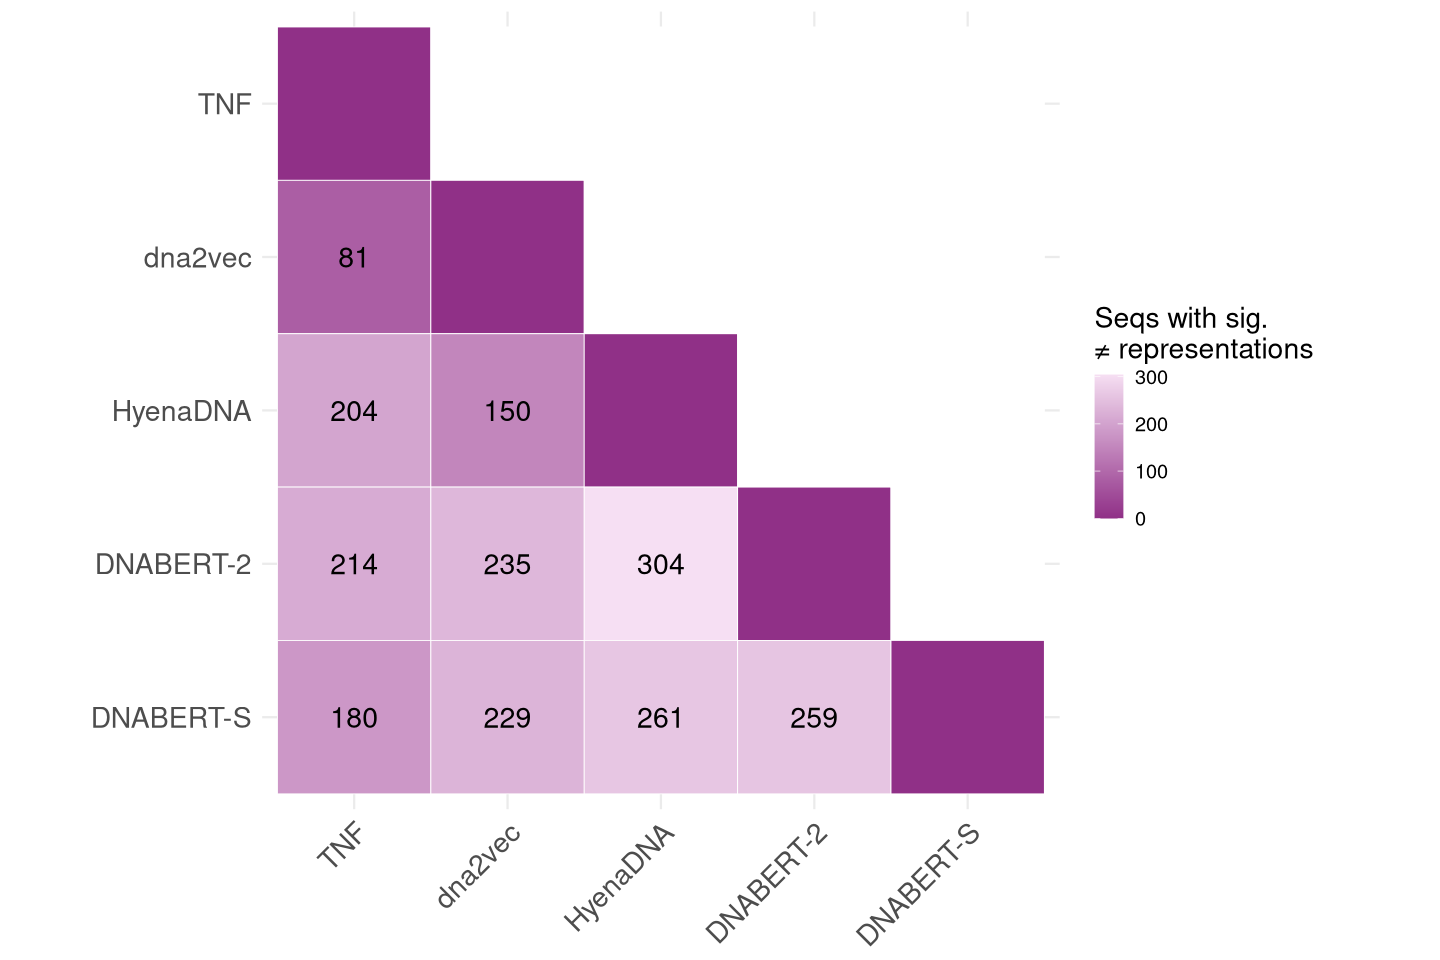

In [16]:
p <- distance_matrix_plot(stat_matrix, metric = "rdpg")
p

In [17]:
ggsave(
  filename = glue("../../../Plots/{sequences_group}_rdpg_stat_distance_matrix_figure_5.png"),
  plot = p,
  width = 8,
  height = 6,
  dpi = 500
)

Warning message:
“Removed 15 rows containing missing values or values outside the scale range (`geom_text()`).”


# 3. Correlation between Jaccard and RDPG results

In [18]:
# Spearman correlation between the method-level Jaccard distances and the RDPG
# significant-difference counts, using only the strictly upper triangle of each
# symmetric matrix (10 pairs).
jacc <- as.matrix(jacc_distance_matrix)
stat <- as.matrix(stat_matrix)

idx <- upper.tri(jacc)

jacc_values <- jacc[idx]
stat_values <- stat[idx]

correlation <- cor(jacc_values, stat_values, method = "spearman")

df <- data.frame(
  jacc = jacc_values,
  stat = stat_values
)

`geom_smooth()` using formula = 'y ~ x'


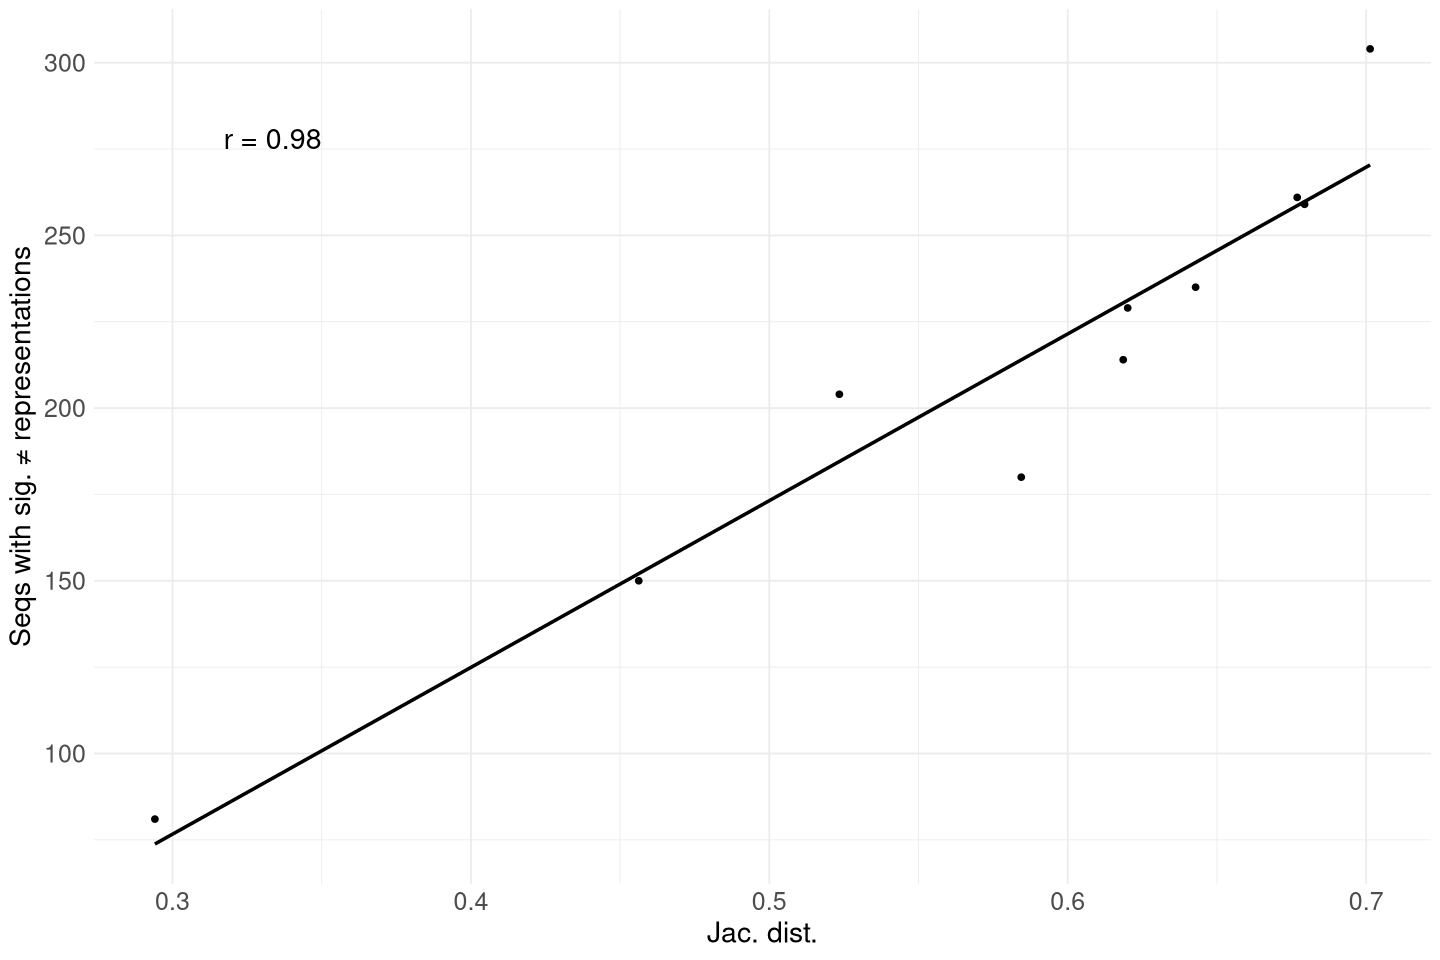

In [19]:
p <- ggplot(df, aes(x = jacc, y = stat)) +
  geom_point() +
  geom_smooth(method = "lm", se = FALSE, color = "black") +
  annotate("text",
    x = 0.35,
    y = 275,
    label = paste("r =", round(correlation, 2)),
    hjust = 1, vjust = 0,
    size = 6) +
  xlab("Jac. dist.") +
  ylab("Seqs with sig. ≠ representations") +
  theme_minimal()+
  theme(
    title = element_text(size = 17),
    axis.text.x = element_text(size = 15),
    axis.text.y = element_text(size = 15),
    axis.title.x = element_text(size = 17),
    axis.title.y = element_text(size = 17),

  )

p

In [20]:
ggsave(
  filename = glue("../../../Plots/{sequences_group}_jaccard_rdpg_stat_correlation.png_figure_S4.png"),
  plot = p,
  width = 7,
  height = 6,
  dpi = 500
)

`geom_smooth()` using formula = 'y ~ x'
